# 🧪 Molecular Toxicity Prediction with Graph Neural Networks

---

**Overview:** This notebook walks through a complete ML pipeline for predicting molecular toxicity using Graph Neural Networks (GNNs). Molecules are naturally represented as graphs, atoms are nodes, bonds are edges making GNNs an ideal architecture.

**Dataset:** [Tox21](https://tox21.gov/) — 7,831 compounds tested against **12 biological targets** (nuclear receptors and stress-response pathways). Labels are binary (toxic / non-toxic) with many missing values (`NaN`).

**Pipeline:**
1. 📦 Environment Setup & Imports
2. 📊 Data Loading & Exploration
3. 🧠 GCN Model Architecture
4. ⚙️ Masked Loss Function & Training Loop
5. 📈 Training Dynamics Visualization
6. 🗺️ Latent Space (t-SNE) Visualization
7. 🔮 Inference on New Molecules

## Cell 1 — Environment Setup & Imports

In [2]:
import warnings
warnings.filterwarnings('ignore')

# ── Core Python ──────────────────────────────────────────────────────────────
import os
import random
import numpy as np
from typing import Optional, Tuple, List

# ── PyTorch ──────────────────────────────────────────────────────────────────
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau

# ── PyTorch Geometric ─────────────────────────────────────────────────────────
from torch_geometric.datasets import MoleculeNet
from torch_geometric.data import Data, DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool

# ── RDKit ─────────────────────────────────────────────────────────────────────
from rdkit import Chem
from rdkit.Chem import Draw, rdMolDescriptors
from rdkit.Chem.Draw import IPythonConsole

# ── Visualisation & Metrics ───────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.lines import Line2D
import networkx as nx
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score

# ── Reproducibility seed ──────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ── Device selection ──────────────────────────────────────────────────────────
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Environment ready.")
print(f"   PyTorch version : {torch.__version__}")
print(f"   Compute device  : {DEVICE}")

✅ Environment ready.
   PyTorch version : 2.4.1+cpu
   Compute device  : cpu


## Cell 2 — Data Loading & Exploration

PyG's `MoleculeNet` automatically downloads the Tox21 dataset and converts every molecule into a PyG `Data` object. Each object contains:
- `data.x` — Node feature matrix (atom features, shape `[num_atoms, 9]`)
- `data.edge_index` — COO-format adjacency (shape `[2, num_bonds*2]`)
- `data.edge_attr` — Bond features
- `data.y` — Multi-label target tensor (shape `[1, 12]`), with `NaN` for missing assays

 Tox21 Dataset Summary
  Total molecules      : 7,823
  Node feature dim     : 9
  Edge feature dim     : 3
  Number of tasks (y)  : 12

  Example molecule (index 0):
    Nodes (atoms)  : 16
    Edges (bonds)  : 17  (stored bidirectionally)
    x shape        : torch.Size([16, 9])
    y shape        : torch.Size([1, 12])
    y values       : tensor([[0., 0., 1., nan, nan, 0., 0., 1., 0., 0., 0., 0.]])

  12 Tox21 Target Assays:
    [ 0] NR-AR
    [ 1] NR-AR-LBD
    [ 2] NR-AhR
    [ 3] NR-Aromatase
    [ 4] NR-ER
    [ 5] NR-ER-LBD
    [ 6] NR-PPAR-gamma
    [ 7] SR-ARE
    [ 8] SR-ATAD5
    [ 9] SR-HSE
    [10] SR-MMP
    [11] SR-p53


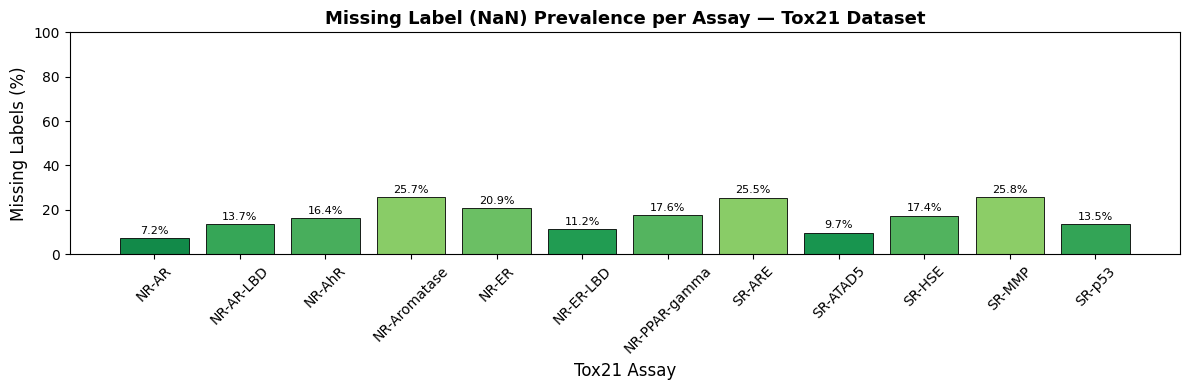


  ⚠️  High NaN rates confirm the need for a MASKED loss function.


In [3]:
dataset = MoleculeNet(root='data/Tox21', name='Tox21')

print("=" * 55)
print(" Tox21 Dataset Summary")
print("=" * 55)
print(f"  Total molecules      : {len(dataset):,}")
print(f"  Node feature dim     : {dataset.num_node_features}")
print(f"  Edge feature dim     : {dataset.num_edge_features}")
print(f"  Number of tasks (y)  : {dataset.num_classes}")

# ── Inspect a single molecule graph ───────────────────────────────────────────
sample = dataset[0]
print(f"\n  Example molecule (index 0):")
print(f"    Nodes (atoms)  : {sample.num_nodes}")
print(f"    Edges (bonds)  : {sample.num_edges // 2}  (stored bidirectionally)")
print(f"    x shape        : {sample.x.shape}")
print(f"    y shape        : {sample.y.shape}")
print(f"    y values       : {sample.y}")

# ── The 12 biological targets ─────────────────────────────────────────────────
TOX21_TASKS = [
    'NR-AR',          # Androgen Receptor (full length)
    'NR-AR-LBD',      # Androgen Receptor (ligand-binding domain)
    'NR-AhR',         # Aryl Hydrocarbon Receptor
    'NR-Aromatase',   # Aromatase
    'NR-ER',          # Estrogen Receptor (full length)
    'NR-ER-LBD',      # Estrogen Receptor (ligand-binding domain)
    'NR-PPAR-gamma',  # Peroxisome Proliferator-Activated Receptor Gamma
    'SR-ARE',         # Antioxidant Response Element
    'SR-ATAD5',       # ATAD5 (DNA Damage)
    'SR-HSE',         # Heat Shock Factor Response Element
    'SR-MMP',         # Mitochondrial Membrane Potential
    'SR-p53',         # Tumor Suppressor p53
]
print(f"\n  12 Tox21 Target Assays:")
for i, t in enumerate(TOX21_TASKS):
    print(f"    [{i:2d}] {t}")

# ── Visualise NaN prevalence across tasks ─────────────────────────────────────
all_labels = torch.cat([d.y for d in dataset], dim=0).numpy()  # (N, 12)
nan_fractions = np.isnan(all_labels).mean(axis=0) * 100

fig, ax = plt.subplots(figsize=(12, 4))
bars = ax.bar(TOX21_TASKS, nan_fractions,
              color=cm.RdYlGn_r(nan_fractions / 100),
              edgecolor='black', linewidth=0.6)
ax.set_xlabel('Tox21 Assay', fontsize=12)
ax.set_ylabel('Missing Labels (%)', fontsize=12)
ax.set_title('Missing Label (NaN) Prevalence per Assay — Tox21 Dataset',
             fontsize=13, fontweight='bold')
ax.set_ylim(0, 100)
ax.tick_params(axis='x', rotation=45)
for bar, val in zip(bars, nan_fractions):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1, f'{val:.1f}%',
            ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.savefig('nan_prevalence.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n  ⚠️  High NaN rates confirm the need for a MASKED loss function.")

## Cell 3 — Visualise a Molecule as a Graph

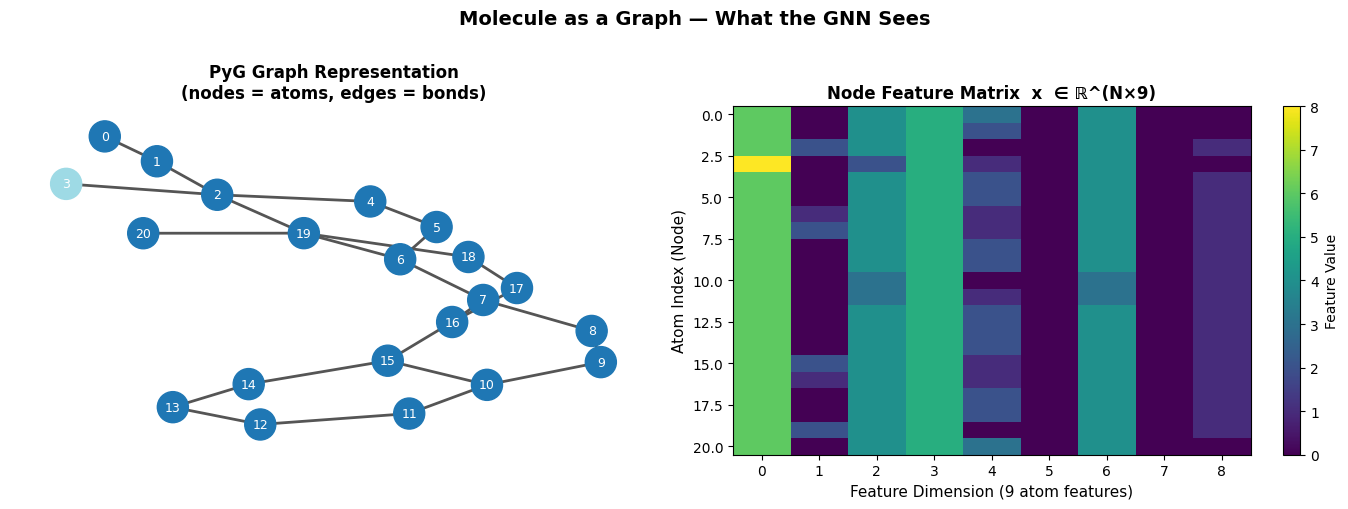

  Molecule stats: 21 atoms, 24 bonds, feature matrix shape: torch.Size([21, 9])


In [5]:
def mol_to_nx(pyg_data: Data) -> nx.Graph:
    """Convert a PyG Data object into a NetworkX graph for visualisation."""
    G = nx.Graph()
    # Add nodes with the first feature dimension (atomic number index) as label
    for i in range(pyg_data.num_nodes):
        G.add_node(i, feature=pyg_data.x[i, 0].item())
    # edge_index is (2, num_edges); add each edge once
    edge_index = pyg_data.edge_index.t().tolist()
    for src, dst in edge_index:
        if src < dst:  # avoid duplicate edges (bidirectional storage)
            G.add_edge(src, dst)
    return G


# Use the first molecule in the dataset (Aspirin-like structure)
sample_mol = dataset[2]  # pick index 2 for a moderately sized molecule
G = mol_to_nx(sample_mol)

# Colour nodes by atomic feature value
node_colors = [G.nodes[n]['feature'] for n in G.nodes]
norm = plt.Normalize(vmin=min(node_colors), vmax=max(node_colors))
cmap = cm.tab20

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Left: Graph representation ────────────────────────────────────────────────
pos = nx.spring_layout(G, seed=SEED)
nx.draw_networkx(
    G, pos, ax=axes[0],
    node_color=[cmap(norm(c)) for c in node_colors],
    node_size=500, font_size=9, font_color='white',
    edge_color='#555555', width=2, with_labels=True
)
axes[0].set_title('PyG Graph Representation\n(nodes = atoms, edges = bonds)',
                  fontsize=12, fontweight='bold')
axes[0].axis('off')

# ── Right: Node feature heatmap ───────────────────────────────────────────────
feature_matrix = sample_mol.x.numpy()  # (num_atoms, 9)
im = axes[1].imshow(feature_matrix, aspect='auto', cmap='viridis')
axes[1].set_xlabel('Feature Dimension (9 atom features)', fontsize=11)
axes[1].set_ylabel('Atom Index (Node)', fontsize=11)
axes[1].set_title('Node Feature Matrix  x  ∈ ℝ^(N×9)',
                  fontsize=12, fontweight='bold')
plt.colorbar(im, ax=axes[1], label='Feature Value')

plt.suptitle('Molecule as a Graph — What the GNN Sees', fontsize=14,
             fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('molecule_graph.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"  Molecule stats: {sample_mol.num_nodes} atoms, "
      f"{sample_mol.num_edges // 2} bonds, "
      f"feature matrix shape: {sample_mol.x.shape}")

## Cell 4 — Dataset Splitting & DataLoaders

In [6]:
BATCH_SIZE = 64  # number of molecules per mini-batch

# ── Shuffle & split ───────────────────────────────────────────────────────────
dataset_shuffled = dataset.shuffle()  # returns a new shuffled Dataset view

n_total  = len(dataset_shuffled)
n_train  = int(n_total * 0.80)
n_val    = n_total - n_train

train_dataset = dataset_shuffled[:n_train]
val_dataset   = dataset_shuffled[n_train:]

print(f"  Dataset split:")
print(f"    Train      : {len(train_dataset):,} molecules")
print(f"    Validation : {len(val_dataset):,} molecules")

# ── DataLoaders ───────────────────────────────────────────────────────────────
# PyG's DataLoader merges multiple molecule graphs into a single large
# disconnected graph batch, enabling efficient GPU parallelism.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,   # reshuffle at every epoch during training
    num_workers=0
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,  # deterministic order for validation
    num_workers=0
)

# ── Quick sanity check on a batch ─────────────────────────────────────────────
batch = next(iter(train_loader))
print(f"\n  First training batch:")
print(f"    batch.x          : {batch.x.shape}      ← all atoms in batch")
print(f"    batch.edge_index : {batch.edge_index.shape}  ← all bonds in batch")
print(f"    batch.y          : {batch.y.shape}      ← labels [batch_size, 12]")
print(f"    batch.batch      : {batch.batch.shape}  ← atom→molecule assignment")
print(f"\n  ✅ DataLoaders ready.")

  Dataset split:
    Train      : 6,258 molecules
    Validation : 1,565 molecules

  First training batch:
    batch.x          : torch.Size([1245, 9])      ← all atoms in batch
    batch.edge_index : torch.Size([2, 2600])  ← all bonds in batch
    batch.y          : torch.Size([64, 12])      ← labels [batch_size, 12]
    batch.batch      : torch.Size([1245])  ← atom→molecule assignment

  ✅ DataLoaders ready.


---
## Cell 5 — GCN Model Architecture

The model follows a standard GNN blueprint:

```
Atom features (x)  →  [GCNConv → ReLU] × 3  →  global_mean_pool  →  Dropout  →  Linear(12)
```

- **GCNConv** layers aggregate neighbour information at each hop (1 hop = 1 bond away).
- **global_mean_pool** collapses all atom embeddings into a single molecule-level vector.
- **Dropout (p=0.5)** prevents overfitting before the final classifier.
- **Linear(12)** outputs raw logits for all 12 toxicity targets simultaneously.

In [7]:
class ToxGCN(nn.Module):
    """
    Graph Convolutional Network for multi-label molecular toxicity prediction.

    Architecture
    ------------
    Three GCNConv message-passing layers with ReLU activations, followed by
    global mean pooling to obtain a fixed-size molecule embedding, then a
    dropout layer and a final linear classifier over 12 Tox21 targets.

    Parameters
    ----------
    in_channels  : int  — Dimension of input node features (9 for Tox21).
    hidden_dim   : int  — Width of hidden GCN layers.
    num_targets  : int  — Number of output tasks (12 for Tox21).
    dropout_p    : float — Dropout probability (default 0.5).
    """

    def __init__(
        self,
        in_channels: int,
        hidden_dim: int = 128,
        num_targets: int = 12,
        dropout_p: float = 0.5,
    ):
        super(ToxGCN, self).__init__()

        # ── Message-passing layers ────────────────────────────────────────────
        # Layer 1: project raw atom features → hidden representation
        self.conv1 = GCNConv(in_channels, hidden_dim)
        # Layer 2: refine atom representations with 1-hop neighbourhood info
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        # Layer 3: capture 2-hop structural patterns
        self.conv3 = GCNConv(hidden_dim, hidden_dim)

        # ── Regularisation ────────────────────────────────────────────────────
        self.dropout = nn.Dropout(p=dropout_p)

        # ── Classifier head ───────────────────────────────────────────────────
        # Maps molecule embedding → 12 raw logits (one per toxicity target)
        self.classifier = nn.Linear(hidden_dim, num_targets)

    # ── Forward pass ─────────────────────────────────────────────────────────
    def forward(
        self,
        x: torch.Tensor,
        edge_index: torch.Tensor,
        batch: torch.Tensor,
        return_embedding: bool = False,
    ) -> torch.Tensor:
        """
        Parameters
        ----------
        x            : Node feature matrix  [N_total_atoms, in_channels]
        edge_index   : COO edge list        [2, E_total_bonds]
        batch        : Atom→molecule map    [N_total_atoms]
        return_embedding : If True, also return the pooled graph embedding
                           (used for t-SNE visualisation).

        Returns
        -------
        logits       : Raw predictions      [batch_size, 12]
        (optionally) embedding : [batch_size, hidden_dim]
        """
        # ── 1. Message Passing ────────────────────────────────────────────────
        # Each GCNConv aggregates: h_v = W · mean({h_u : u ∈ N(v) ∪ {v}})
        h = F.relu(self.conv1(x, edge_index))      # (N_atoms, hidden_dim)
        h = F.relu(self.conv2(h, edge_index))      # (N_atoms, hidden_dim)
        h = F.relu(self.conv3(h, edge_index))      # (N_atoms, hidden_dim)

        # ── 2. Graph-level Pooling ────────────────────────────────────────────
        # Collapse variable-size atom embeddings → fixed-size molecule vector
        # global_mean_pool computes the mean over all atoms belonging to each
        # molecule in the batch.
        embedding = global_mean_pool(h, batch)     # (batch_size, hidden_dim)

        # ── 3. Dropout + Classification ───────────────────────────────────────
        out = self.dropout(embedding)
        logits = self.classifier(out)              # (batch_size, 12)

        if return_embedding:
            return logits, embedding
        return logits


# ── Instantiate model ─────────────────────────────────────────────────────────
IN_CHANNELS = dataset.num_node_features   # 9
HIDDEN_DIM  = 128
NUM_TARGETS = 12

model = ToxGCN(
    in_channels=IN_CHANNELS,
    hidden_dim=HIDDEN_DIM,
    num_targets=NUM_TARGETS,
    dropout_p=0.5,
).to(DEVICE)

# ── Parameter count ───────────────────────────────────────────────────────────
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\n  Total trainable parameters: {total_params:,}")

ToxGCN(
  (conv1): GCNConv(9, 128)
  (conv2): GCNConv(128, 128)
  (conv3): GCNConv(128, 128)
  (dropout): Dropout(p=0.5, inplace=False)
  (classifier): Linear(in_features=128, out_features=12, bias=True)
)

  Total trainable parameters: 35,852


---
## Cell 6 — Masked Loss Function

The Tox21 dataset has many missing labels (`NaN`). A standard `BCEWithLogitsLoss` would treat `NaN` as a numeric value and corrupt gradients.

**Solution:** Build a `masked_bce_loss` that:
1. Creates a boolean mask from `~torch.isnan(y)`
2. Zeroes out `NaN` positions in `y` (so PyTorch doesn't explode)
3. Computes per-element BCE loss across the full tensor
4. Applies the mask — only valid entries contribute to the mean

In [8]:
def masked_bce_loss(
    logits: torch.Tensor,
    targets: torch.Tensor,
) -> torch.Tensor:
    """
    Binary Cross-Entropy loss that ignores NaN-labelled entries.

    Tox21 labels are sparse — many (molecule, assay) pairs were never tested.
    These show up as NaN in `targets`. This function dynamically builds a mask
    so only valid (molecule, assay) pairs contribute to the gradient.

    Parameters
    ----------
    logits  : Raw model output  [batch_size, 12]  (before sigmoid)
    targets : Ground-truth labels [batch_size, 12] (may contain NaN)

    Returns
    -------
    Scalar loss averaged over valid entries only.

    Example
    -------
    >>> y = torch.tensor([[1.0, float('nan'), 0.0]])
    >>> l = torch.tensor([[0.2, 0.9, -0.5]])   # raw logits
    >>> masked_bce_loss(l, y)  # NaN column ignored
    """
    # Step 1: Build a boolean mask — True where label exists
    mask = ~torch.isnan(targets)              # shape: [batch_size, 12]

    # Step 2: Replace NaN with 0.0 to avoid NaN propagation in backward pass
    # The mask ensures these positions contribute 0 to the final loss.
    targets_clean = targets.clone()
    targets_clean[~mask] = 0.0

    # Step 3: Compute element-wise BCE loss (no reduction yet)
    loss_per_element = F.binary_cross_entropy_with_logits(
        logits,
        targets_clean,
        reduction='none'                      # shape: [batch_size, 12]
    )

    # Step 4: Zero out loss at NaN positions, then average over valid entries
    masked_loss = loss_per_element * mask.float()

    # Guard against the degenerate case where the entire batch has no valid labels
    n_valid = mask.sum().clamp(min=1)

    return masked_loss.sum() / n_valid


# ── Quick unit-test ───────────────────────────────────────────────────────────
print("  Testing masked_bce_loss ...")

# Correct test: NaN only in targets (missing assay labels), never in logits
_logits  = torch.tensor([[2.0, -1.0, 0.5,  0.8]])   # model always produces finite logits
_targets = torch.tensor([[1.0, float('nan'), 0.0, float('nan')]])  # 2 missing assays

_loss = masked_bce_loss(_logits, _targets)
print(f"    Loss on 2 valid entries: {_loss.item():.4f}  (finite: {_loss.isfinite().item()})")
assert _loss.isfinite(), "Loss should be a finite scalar!"

# Verify it matches plain BCE on only the valid positions
_expected = F.binary_cross_entropy_with_logits(
    torch.tensor([[2.0, 0.5]]),   # only the non-NaN positions
    torch.tensor([[1.0, 0.0]]),
)
assert torch.allclose(_loss, _expected), "Masked loss doesn't match expected!"

print("  ✅ Masked loss function working correctly.")

  Testing masked_bce_loss ...
    Loss on 2 valid entries: 0.5505  (finite: True)
  ✅ Masked loss function working correctly.


---
## Cell 7 — Training & Validation Loop with Early Stopping

The training engine includes:
- **Adam** optimiser with a learning rate scheduler (reduces LR on plateau)
- **Early stopping** (patience = 20 epochs) — training halts when validation loss stops improving
- **Best model checkpointing** — `torch.save()` preserves the best weights

In [9]:
# ── Optimiser & Scheduler ─────────────────────────────────────────────────────
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 1e-4   # L2 regularisation on weights

optimiser = Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

# Reduce LR by 0.5 if validation loss hasn't improved for 10 epochs
scheduler = ReduceLROnPlateau(
    optimiser, mode='min', factor=0.5, patience=10, verbose=True
)

# ── Early Stopping State ──────────────────────────────────────────────────────
PATIENCE          = 20          # epochs to wait before stopping
BEST_MODEL_PATH   = 'best_tox_gcn.pt'

best_val_loss     = float('inf')
patience_counter  = 0
early_stopped     = False

# ── History containers ────────────────────────────────────────────────────────
history = {'train_loss': [], 'val_loss': []}


# ────────────────────────────────────────────────────────────────────────────
def train_one_epoch(model, loader, optimiser) -> float:
    """
    Run one full pass over the training set.

    Returns
    -------
    Average masked BCE loss over all training batches.
    """
    model.train()  # activate dropout, enable gradient computation
    total_loss = 0.0

    for batch in loader:
        batch = batch.to(DEVICE)

        # Zero accumulated gradients from the previous step
        optimiser.zero_grad()

        # Forward pass — obtain raw logits
        logits = model(batch.x.float(), batch.edge_index, batch.batch)
        logits = torch.nan_to_num(logits, nan=0.0)  # safety net only
        loss   = masked_bce_loss(logits, batch.y.float())

        # batch.y shape: (batch_size, 12) — may contain NaN
        targets = batch.y.float()

        # Compute masked loss (only valid labels contribute)
        loss = masked_bce_loss(logits, targets)

        # Backward pass + gradient update
        loss.backward()
        optimiser.step()

        total_loss += loss.item()

    return total_loss / len(loader)


@torch.no_grad()  # disable gradient tracking for efficiency during evaluation
def evaluate(model, loader) -> float:
    """
    Evaluate the model on a given DataLoader.

    Returns
    -------
    Average masked BCE loss over all batches.
    """
    model.eval()  # deactivate dropout
    total_loss = 0.0

    for batch in loader:
        batch  = batch.to(DEVICE)
        logits = model(batch.x.float(), batch.edge_index, batch.batch)
        loss   = masked_bce_loss(logits, batch.y.float())
        total_loss += loss.item()

    return total_loss / len(loader)


print("  ✅ Training infrastructure ready.")
print(f"     Optimiser   : Adam (lr={LEARNING_RATE}, wd={WEIGHT_DECAY})")
print(f"     Scheduler   : ReduceLROnPlateau (factor=0.5, patience=10)")
print(f"     Early stop  : patience={PATIENCE} epochs")
print(f"     Checkpoint  : '{BEST_MODEL_PATH}'")

  ✅ Training infrastructure ready.
     Optimiser   : Adam (lr=0.001, wd=0.0001)
     Scheduler   : ReduceLROnPlateau (factor=0.5, patience=10)
     Early stop  : patience=20 epochs
     Checkpoint  : 'best_tox_gcn.pt'


---
## Cell 8 — Run Training

In [10]:
MAX_EPOCHS = 200  # upper bound; early stopping will likely trigger first

print(f"{'Epoch':>6} | {'Train Loss':>11} | {'Val Loss':>10} | {'LR':>10} | {'Note'}")
print("-" * 65)

for epoch in range(1, MAX_EPOCHS + 1):

    # ── Train ─────────────────────────────────────────────────────────────────
    train_loss = train_one_epoch(model, train_loader, optimiser)

    # ── Validate ──────────────────────────────────────────────────────────────
    val_loss = evaluate(model, val_loader)

    # ── LR Scheduling ─────────────────────────────────────────────────────────
    scheduler.step(val_loss)
    current_lr = optimiser.param_groups[0]['lr']

    # ── Logging ───────────────────────────────────────────────────────────────
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)

    note = ''
    # ── Checkpointing ─────────────────────────────────────────────────────────
    if val_loss < best_val_loss:
        best_val_loss    = val_loss
        patience_counter = 0
        # Save the full model state dictionary
        torch.save({
            'epoch'           : epoch,
            'model_state_dict': model.state_dict(),
            'val_loss'        : val_loss,
        }, BEST_MODEL_PATH)
        note = '✅ best'
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            note = '🛑 early stop'
            print(f"{epoch:>6} | {train_loss:>11.4f} | {val_loss:>10.4f} | "
                  f"{current_lr:>10.2e} | {note}")
            early_stopped = True
            break

    # Print every 5 epochs or on important events
    if epoch % 5 == 0 or note:
        print(f"{epoch:>6} | {train_loss:>11.4f} | {val_loss:>10.4f} | "
              f"{current_lr:>10.2e} | {note}")

print("-" * 65)
stop_reason = "early stopping" if early_stopped else "max epochs reached"
print(f"\n  Training complete ({stop_reason}).")
print(f"  Best validation loss: {best_val_loss:.4f}")
print(f"  Checkpoint saved to : '{BEST_MODEL_PATH}'")

 Epoch |  Train Loss |   Val Loss |         LR | Note
-----------------------------------------------------------------
     1 |      0.3150 |     0.2360 |   1.00e-03 | ✅ best
     2 |      0.2604 |     0.2271 |   1.00e-03 | ✅ best
     3 |      0.2534 |     0.2253 |   1.00e-03 | ✅ best
     4 |      0.2511 |     0.2231 |   1.00e-03 | ✅ best
     5 |      0.2487 |     0.2233 |   1.00e-03 | 
     6 |      0.2474 |     0.2204 |   1.00e-03 | ✅ best
     8 |      0.2430 |     0.2199 |   1.00e-03 | ✅ best
     9 |      0.2439 |     0.2176 |   1.00e-03 | ✅ best
    10 |      0.2416 |     0.2182 |   1.00e-03 | 
    12 |      0.2411 |     0.2167 |   1.00e-03 | ✅ best
    13 |      0.2425 |     0.2159 |   1.00e-03 | ✅ best
    15 |      0.2404 |     0.2146 |   1.00e-03 | ✅ best
    17 |      0.2384 |     0.2144 |   1.00e-03 | ✅ best
    20 |      0.2383 |     0.2136 |   1.00e-03 | ✅ best
    24 |      0.2363 |     0.2135 |   1.00e-03 | ✅ best
    25 |      0.2365 |     0.2125 |   1.00e-03 | ✅ b

---
## Cell 9 — Load Best Model & Compute ROC-AUC

Reload the best checkpoint and compute per-task ROC-AUC scores, which are the standard metric for imbalanced binary classification tasks like Tox21.

In [11]:
# ── Reload best weights ───────────────────────────────────────────────────────
checkpoint = torch.load(BEST_MODEL_PATH, map_location=DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])
print(f"  Loaded best model from epoch {checkpoint['epoch']} "
      f"(val_loss={checkpoint['val_loss']:.4f})")


@torch.no_grad()
def collect_predictions(model, loader) -> Tuple[np.ndarray, np.ndarray]:
    """
    Run the model over a DataLoader and collect all predictions and labels.

    Returns
    -------
    all_probs  : Predicted probabilities [N, 12]  (after sigmoid)
    all_labels : Ground-truth labels     [N, 12]  (NaN preserved)
    """
    model.eval()
    probs_list, labels_list = [], []

    for batch in loader:
        batch  = batch.to(DEVICE)
        logits = model(batch.x.float(), batch.edge_index, batch.batch)
        probs  = torch.sigmoid(logits).cpu().numpy()
        labels = batch.y.cpu().numpy()
        probs_list.append(probs)
        labels_list.append(labels)

    return np.vstack(probs_list), np.vstack(labels_list)


val_probs, val_labels = collect_predictions(model, val_loader)

# ── Per-task ROC-AUC (masking NaN) ───────────────────────────────────────────
print(f"\n  {'Task':<18} | {'ROC-AUC':>8} | {'Valid Samples':>14}")
print("  " + "-" * 48)

auc_scores = []
for i, task in enumerate(TOX21_TASKS):
    valid_mask    = ~np.isnan(val_labels[:, i])
    y_true        = val_labels[:, i][valid_mask]
    y_pred        = val_probs[:, i][valid_mask]
    n_valid       = valid_mask.sum()

    if len(np.unique(y_true)) < 2:
        # ROC-AUC undefined if only one class present in validation
        auc = float('nan')
    else:
        auc = roc_auc_score(y_true, y_pred)
    auc_scores.append(auc)
    print(f"  {task:<18} | {auc:>8.4f} | {n_valid:>14,}")

mean_auc = np.nanmean(auc_scores)
print("  " + "-" * 48)
print(f"  {'MEAN AUC':<18} | {mean_auc:>8.4f} |")

  Loaded best model from epoch 126 (val_loss=0.2032)

  Task               |  ROC-AUC |  Valid Samples
  ------------------------------------------------
  NR-AR              |   0.8405 |          1,449
  NR-AR-LBD          |   0.8481 |          1,340
  NR-AhR             |   0.8242 |          1,301
  NR-Aromatase       |   0.7616 |          1,166
  NR-ER              |   0.7002 |          1,238
  NR-ER-LBD          |   0.7667 |          1,381
  NR-PPAR-gamma      |   0.6764 |          1,279
  SR-ARE             |   0.7046 |          1,185
  SR-ATAD5           |   0.7849 |          1,409
  SR-HSE             |   0.7347 |          1,319
  SR-MMP             |   0.8337 |          1,142
  SR-p53             |   0.7703 |          1,350
  ------------------------------------------------
  MEAN AUC           |   0.7705 |


---
## Cell 10 — Visualisation 1: Training Dynamics

A dual-line plot of training vs. validation loss over all epochs. Divergence between the two curves indicates overfitting.

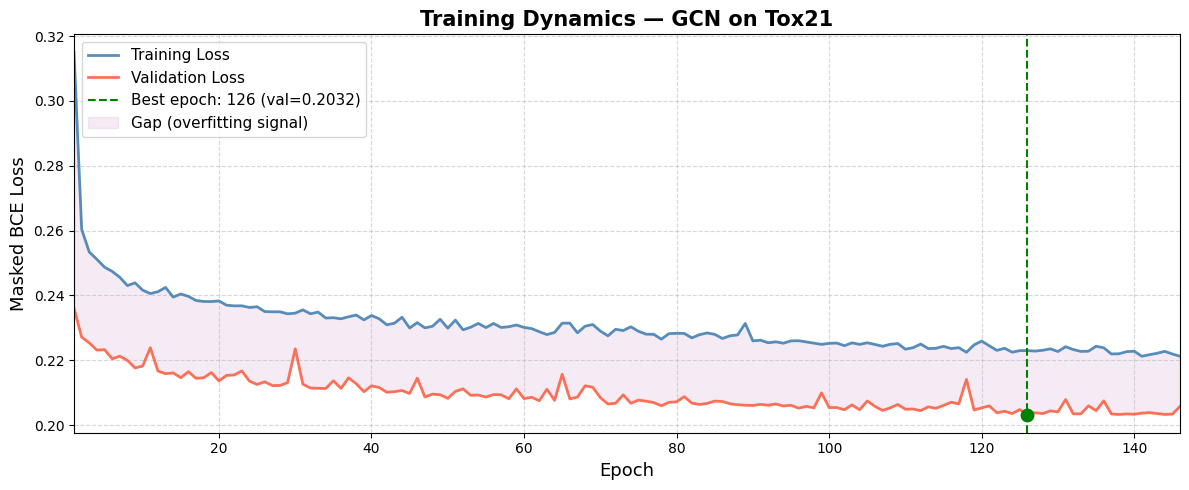

  Plot saved: training_dynamics.png


In [12]:
epochs_ran = range(1, len(history['train_loss']) + 1)

fig, ax = plt.subplots(figsize=(12, 5))

# ── Loss curves ───────────────────────────────────────────────────────────────
ax.plot(epochs_ran, history['train_loss'],
        label='Training Loss', color='steelblue', linewidth=2, alpha=0.9)
ax.plot(epochs_ran, history['val_loss'],
        label='Validation Loss', color='tomato', linewidth=2, alpha=0.9)

# ── Highlight the best epoch ──────────────────────────────────────────────────
best_epoch = int(np.argmin(history['val_loss'])) + 1
best_loss  = min(history['val_loss'])
ax.axvline(x=best_epoch, color='green', linestyle='--', linewidth=1.5,
           label=f'Best epoch: {best_epoch} (val={best_loss:.4f})')
ax.scatter([best_epoch], [best_loss], color='green', zorder=5, s=80)

# ── Shading ───────────────────────────────────────────────────────────────────
ax.fill_between(epochs_ran, history['train_loss'], history['val_loss'],
                alpha=0.08, color='purple', label='Gap (overfitting signal)')

ax.set_xlabel('Epoch', fontsize=13)
ax.set_ylabel('Masked BCE Loss', fontsize=13)
ax.set_title('Training Dynamics — GCN on Tox21',
             fontsize=15, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_xlim(1, max(epochs_ran))

plt.tight_layout()
plt.savefig('training_dynamics.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"  Plot saved: training_dynamics.png")

---
## Cell 11 — Visualisation 2: Latent Space via t-SNE

We extract the **graph embeddings** (the 128-dimensional vectors output by `global_mean_pool`) for every molecule in the validation set, then project them to 2D using **t-SNE**. Points are coloured by the presence of a toxicity label for the first task (`NR-AR`), giving us a qualitative view of how the GNN separates chemical space.

  Extracting latent embeddings for validation set ...
  Embeddings shape: (1565, 128)
  Running t-SNE (this takes ~30–60 seconds) ...
  t-SNE complete. Projection shape: (1565, 2)


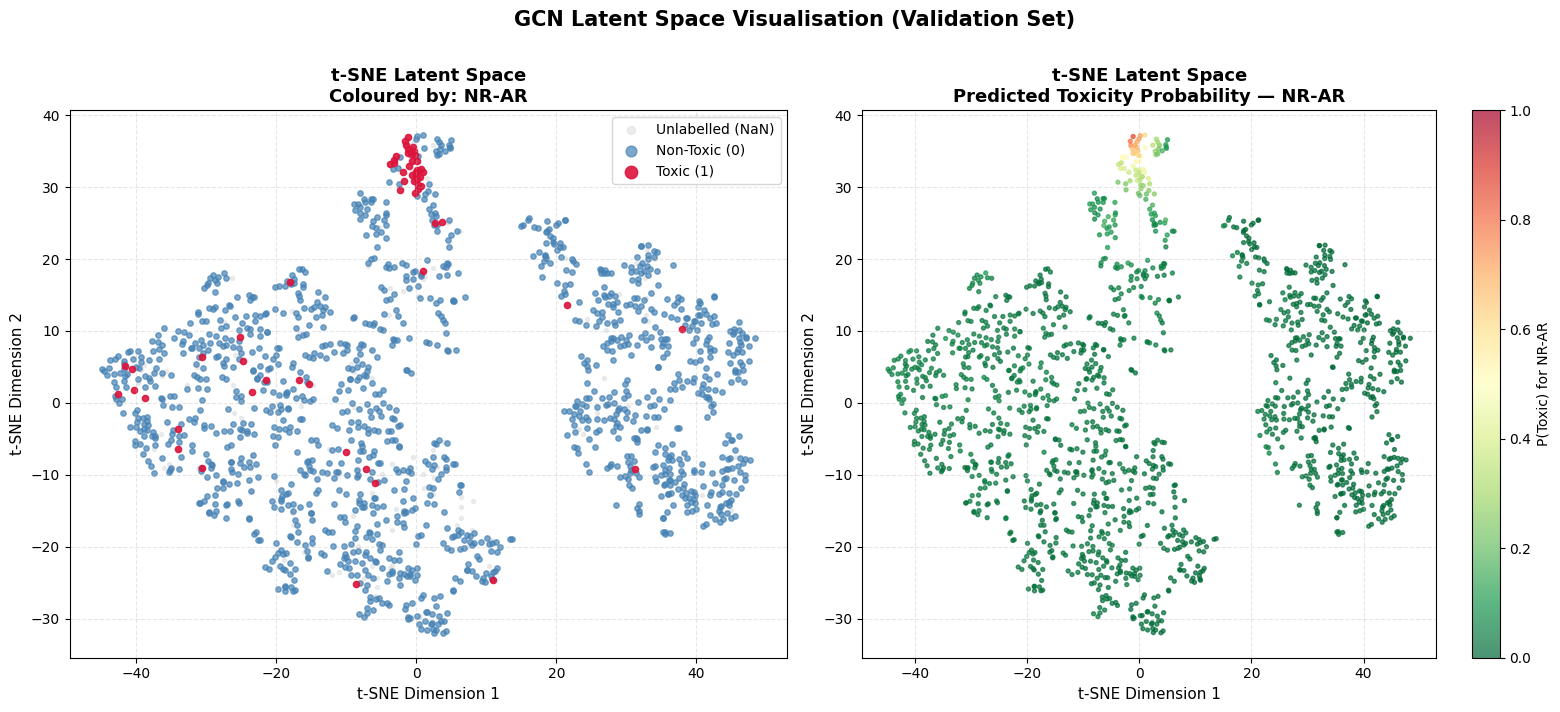

  Plot saved: tsne_latent_space.png


In [13]:
@torch.no_grad()
def extract_embeddings(
    model: nn.Module,
    loader: DataLoader,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Extract graph-level embeddings from the global_mean_pool layer.

    Returns
    -------
    embeddings : (N_val, hidden_dim) float32 array
    labels     : (N_val, 12) float32 array  (NaN preserved)
    """
    model.eval()
    emb_list, label_list = [], []

    for batch in loader:
        batch = batch.to(DEVICE)
        # return_embedding=True returns (logits, embedding) tuple
        _, emb = model(
            batch.x.float(), batch.edge_index, batch.batch,
            return_embedding=True
        )
        emb_list.append(emb.cpu().numpy())
        label_list.append(batch.y.cpu().numpy())

    return np.vstack(emb_list), np.vstack(label_list)


print("  Extracting latent embeddings for validation set ...")
embeddings, emb_labels = extract_embeddings(model, val_loader)
print(f"  Embeddings shape: {embeddings.shape}")

# ── t-SNE projection (reduce 128D → 2D) ──────────────────────────────────────
print("  Running t-SNE (this takes ~30–60 seconds) ...")
tsne = TSNE(
    n_components=2,
    perplexity=40,
    max_iter=1000,
    random_state=SEED,
    verbose=0,
)
emb_2d = tsne.fit_transform(embeddings)  # (N_val, 2)
print(f"  t-SNE complete. Projection shape: {emb_2d.shape}")

# ── Plot: colour by NR-AR label (task index 0) ────────────────────────────────
task_idx   = 0  # NR-AR
task_label = TOX21_TASKS[task_idx]
y_col      = emb_labels[:, task_idx]

# Separate valid points into toxic (1) / non-toxic (0) / unlabelled (NaN)
mask_pos = (y_col == 1.0)
mask_neg = (y_col == 0.0)
mask_nan = np.isnan(y_col)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# ── Left: Coarse 3-class colouring ───────────────────────────────────────────
ax = axes[0]
ax.scatter(emb_2d[mask_nan, 0], emb_2d[mask_nan, 1],
           c='lightgrey', s=8, alpha=0.4, label='Unlabelled (NaN)')
ax.scatter(emb_2d[mask_neg, 0], emb_2d[mask_neg, 1],
           c='steelblue', s=15, alpha=0.7, label='Non-Toxic (0)')
ax.scatter(emb_2d[mask_pos, 0], emb_2d[mask_pos, 1],
           c='crimson', s=20, alpha=0.9, label='Toxic (1)')
ax.set_title(f't-SNE Latent Space\nColoured by: {task_label}',
             fontsize=13, fontweight='bold')
ax.set_xlabel('t-SNE Dimension 1', fontsize=11)
ax.set_ylabel('t-SNE Dimension 2', fontsize=11)
ax.legend(fontsize=10, markerscale=2)
ax.grid(True, linestyle='--', alpha=0.3)

# ── Right: Predicted probability gradient ────────────────────────────────────
ax = axes[1]
pred_prob_col = val_probs[:, task_idx]  # predicted P(toxic) for NR-AR
sc = ax.scatter(emb_2d[:, 0], emb_2d[:, 1],
                c=pred_prob_col, cmap='RdYlGn_r',
                s=8, alpha=0.7, vmin=0, vmax=1)
plt.colorbar(sc, ax=ax, label=f'P(Toxic) for {task_label}')
ax.set_title(f't-SNE Latent Space\nPredicted Toxicity Probability — {task_label}',
             fontsize=13, fontweight='bold')
ax.set_xlabel('t-SNE Dimension 1', fontsize=11)
ax.set_ylabel('t-SNE Dimension 2', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.3)

plt.suptitle('GCN Latent Space Visualisation (Validation Set)',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('tsne_latent_space.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Plot saved: tsne_latent_space.png")

---
## Cell 12 — Visualisation 3: Per-Task ROC-AUC Bar Chart

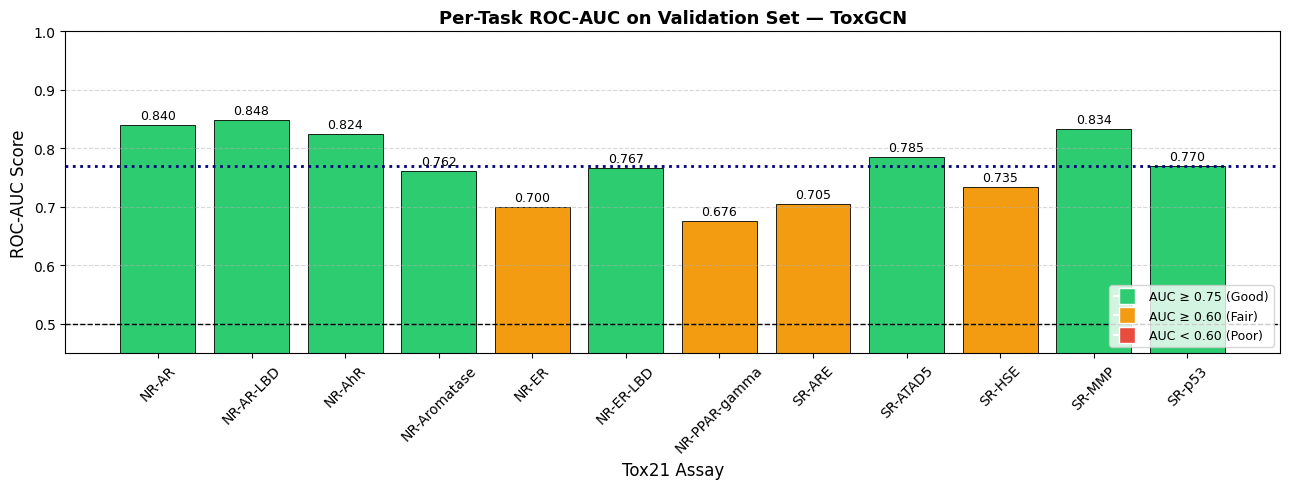

  Plot saved: per_task_auc.png


In [14]:
fig, ax = plt.subplots(figsize=(13, 5))

valid_aucs = [(t, a) for t, a in zip(TOX21_TASKS, auc_scores) if not np.isnan(a)]
tasks_plot, aucs_plot = zip(*valid_aucs)

# Colour bars: green if AUC ≥ 0.75, amber if ≥ 0.60, red otherwise
bar_colors = ['#2ecc71' if a >= 0.75 else '#f39c12' if a >= 0.60 else '#e74c3c'
              for a in aucs_plot]

bars = ax.bar(tasks_plot, aucs_plot, color=bar_colors,
              edgecolor='black', linewidth=0.6)
ax.axhline(y=0.5, color='black', linestyle='--', linewidth=1, label='Random baseline (0.5)')
ax.axhline(y=mean_auc, color='navy', linestyle=':', linewidth=2,
           label=f'Mean AUC = {mean_auc:.3f}')

for bar, val in zip(bars, aucs_plot):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.005,
            f'{val:.3f}', ha='center', va='bottom', fontsize=9)

# Legend patches
legend_elements = [
    Line2D([0], [0], marker='s', color='w', markerfacecolor='#2ecc71', markersize=12, label='AUC ≥ 0.75 (Good)'),
    Line2D([0], [0], marker='s', color='w', markerfacecolor='#f39c12', markersize=12, label='AUC ≥ 0.60 (Fair)'),
    Line2D([0], [0], marker='s', color='w', markerfacecolor='#e74c3c', markersize=12, label='AUC < 0.60 (Poor)'),
]
ax.legend(handles=legend_elements + ax.get_legend_handles_labels()[0][len(legend_elements):],
          fontsize=9, loc='lower right')
ax.set_ylim(0.45, 1.0)
ax.set_xlabel('Tox21 Assay', fontsize=12)
ax.set_ylabel('ROC-AUC Score', fontsize=12)
ax.set_title('Per-Task ROC-AUC on Validation Set — ToxGCN',
             fontsize=13, fontweight='bold')
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('per_task_auc.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Plot saved: per_task_auc.png")

---
## Cell 13 — Inference on New Molecules

The `predict_new_molecule` function converts any SMILES string into a PyG graph on-the-fly using RDKit, runs it through the trained model, and prints a human-readable toxicity probability report for all 12 Tox21 targets.

**SMILES** (Simplified Molecular-Input Line-Entry System) is the standard text representation of chemical structures. For example:
- Aspirin: `CC(=O)OC1=CC=CC=C1C(=O)O`
- Caffeine: `CN1C=NC2=C1C(=O)N(C(=O)N2C)C`
- Ethanol: `CCO`

In [15]:
def smiles_to_pyg(smiles: str) -> Optional[Data]:
    """
    Convert a SMILES string into a PyG Data object.

    Node features (x): Each atom is encoded as a 9-dimensional feature vector
    matching the Tox21 MoleculeNet featurisation:
        [0] Atomic number (normalised)
        [1] Chirality index
        [2] Degree
        [3] Formal charge
        [4] Number of Hs
        [5] Number of radical electrons
        [6] Hybridisation
        [7] Is aromatic
        [8] Is in ring

    Edge indices: COO format — bidirectional bond pairs.

    Parameters
    ----------
    smiles : str — A valid SMILES string.

    Returns
    -------
    PyG Data object or None if the SMILES is invalid.
    """
    # ── Parse SMILES with RDKit ───────────────────────────────────────────────
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        print(f"  ❌ RDKit could not parse SMILES: '{smiles}'")
        return None

    # Add explicit Hs so hydrogen count is directly accessible
    mol = Chem.AddHs(mol)
    Chem.RemoveHs(mol)          # remove again to keep heavy-atom graph

    # ── Node (atom) features ──────────────────────────────────────────────────
    # Map hybridisation type → integer index for one consistent encoding
    hybridisation_map = {
        Chem.rdchem.HybridizationType.S    : 0,
        Chem.rdchem.HybridizationType.SP   : 1,
        Chem.rdchem.HybridizationType.SP2  : 2,
        Chem.rdchem.HybridizationType.SP3  : 3,
        Chem.rdchem.HybridizationType.SP3D : 4,
        Chem.rdchem.HybridizationType.SP3D2: 5,
        Chem.rdchem.HybridizationType.OTHER: 6,
    }

    node_features = []
    for atom in mol.GetAtoms():
        feat = [
            atom.GetAtomicNum(),                       # [0] atomic number
            int(atom.GetChiralTag()),                  # [1] chirality
            atom.GetDegree(),                          # [2] degree
            atom.GetFormalCharge(),                    # [3] formal charge
            atom.GetTotalNumHs(),                      # [4] number of Hs
            atom.GetNumRadicalElectrons(),             # [5] radical electrons
            hybridisation_map.get(
                atom.GetHybridization(), 6),           # [6] hybridisation
            int(atom.GetIsAromatic()),                 # [7] aromatic flag
            int(atom.IsInRing()),                      # [8] in ring
        ]
        node_features.append(feat)

    x = torch.tensor(node_features, dtype=torch.float)

    # ── Edge (bond) index ─────────────────────────────────────────────────────
    # Store each bond twice (u→v and v→u) to create an undirected graph
    src_list, dst_list = [], []
    for bond in mol.GetBonds():
        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()
        src_list += [i, j]
        dst_list += [j, i]

    if len(src_list) == 0:
        # Single-atom molecule (e.g., [He]) — add self-loop so GCNConv doesn't fail
        edge_index = torch.tensor([[0], [0]], dtype=torch.long)
    else:
        edge_index = torch.tensor([src_list, dst_list], dtype=torch.long)

    return Data(x=x, edge_index=edge_index)


# ────────────────────────────────────────────────────────────────────────────

@torch.no_grad()
def predict_new_molecule(
    smiles_string: str,
    model: nn.Module,
    threshold: float = 0.5,
) -> Optional[np.ndarray]:
    """
    Predict toxicity probabilities for a single molecule given as a SMILES string.

    Parameters
    ----------
    smiles_string : str   — SMILES representation of the molecule.
    model         : nn.Module — Trained ToxGCN model.
    threshold     : float — Decision boundary for toxic/non-toxic label (default 0.5).

    Returns
    -------
    probs : np.ndarray of shape (12,) with probabilities in [0, 1],
            or None if the SMILES is invalid.
    """
    # ── Step 1: SMILES → PyG Data ─────────────────────────────────────────────
    data = smiles_to_pyg(smiles_string)
    if data is None:
        return None

    # ── Step 2: Move to device ────────────────────────────────────────────────
    data = data.to(DEVICE)

    # batch tensor: all atoms belong to molecule 0 (single-molecule inference)
    batch_vec = torch.zeros(data.num_nodes, dtype=torch.long, device=DEVICE)

    # ── Step 3: Forward pass ──────────────────────────────────────────────────
    model.eval()
    logits = model(data.x.float(), data.edge_index, batch_vec)  # (1, 12)

    # ── Step 4: Sigmoid → probabilities ──────────────────────────────────────
    probs = torch.sigmoid(logits).squeeze(0).cpu().numpy()  # (12,)

    # ── Step 5: Pretty-print results ─────────────────────────────────────────
    mol = Chem.MolFromSmiles(smiles_string)
    formula = rdMolDescriptors.CalcMolFormula(mol) if mol else '?'

    print("\n" + "=" * 62)
    print(f"  🧪 Toxicity Prediction Report")
    print(f"  SMILES  : {smiles_string}")
    print(f"  Formula : {formula}")
    print(f"  Atoms   : {data.num_nodes}")
    print("=" * 62)
    print(f"  {'Assay':<18} | {'Probability':>11} | {'Prediction':>12}")
    print("  " + "-" * 48)

    for task, prob in zip(TOX21_TASKS, probs):
        label = '⚠️  TOXIC' if prob >= threshold else '✅ Non-Toxic'
        bar   = '█' * int(prob * 20) + '░' * (20 - int(prob * 20))
        print(f"  {task:<18} | {prob * 100:>9.1f}%  | {label}")
    print("=" * 62)

    return probs


print("  ✅ predict_new_molecule() ready.")

  ✅ predict_new_molecule() ready.


---
## Cell 14 — Run Inference: Aspirin, Caffeine & a Known Toxin

In [16]:
# ── Example 1: Aspirin ────────────────────────────────────────────────────────
print("\n" + "#" * 65)
print("  EXAMPLE 1 — Aspirin (Acetylsalicylic acid)")
print("#" * 65)
aspirin_smiles = 'CC(=O)OC1=CC=CC=C1C(=O)O'
probs_aspirin = predict_new_molecule(aspirin_smiles, model)

# ── Example 2: Caffeine ───────────────────────────────────────────────────────
print("\n" + "#" * 65)
print("  EXAMPLE 2 — Caffeine")
print("#" * 65)
caffeine_smiles = 'CN1C=NC2=C1C(=O)N(C(=O)N2C)C'
probs_caffeine = predict_new_molecule(caffeine_smiles, model)

# ── Example 3: Bisphenol A (known endocrine disruptor) ────────────────────────
print("\n" + "#" * 65)
print("  EXAMPLE 3 — Bisphenol A (BPA, known endocrine disruptor)")
print("#" * 65)
bpa_smiles = 'CC(C)(c1ccc(O)cc1)c1ccc(O)cc1'
probs_bpa = predict_new_molecule(bpa_smiles, model)

# ── Example 4: Ethanol ────────────────────────────────────────────────────────
print("\n" + "#" * 65)
print("  EXAMPLE 4 — Ethanol")
print("#" * 65)
ethanol_smiles = 'CCO'
probs_ethanol = predict_new_molecule(ethanol_smiles, model)


#################################################################
  EXAMPLE 1 — Aspirin (Acetylsalicylic acid)
#################################################################

  🧪 Toxicity Prediction Report
  SMILES  : CC(=O)OC1=CC=CC=C1C(=O)O
  Formula : C9H8O4
  Atoms   : 21
  Assay              | Probability |   Prediction
  ------------------------------------------------
  NR-AR              |      23.1%  | ✅ Non-Toxic
  NR-AR-LBD          |      26.6%  | ✅ Non-Toxic
  NR-AhR             |      27.6%  | ✅ Non-Toxic
  NR-Aromatase       |      26.2%  | ✅ Non-Toxic
  NR-ER              |      29.4%  | ✅ Non-Toxic
  NR-ER-LBD          |      29.7%  | ✅ Non-Toxic
  NR-PPAR-gamma      |      23.0%  | ✅ Non-Toxic
  SR-ARE             |      41.6%  | ✅ Non-Toxic
  SR-ATAD5           |      20.3%  | ✅ Non-Toxic
  SR-HSE             |      30.4%  | ✅ Non-Toxic
  SR-MMP             |      47.3%  | ✅ Non-Toxic
  SR-p53             |      33.0%  | ✅ Non-Toxic

#############################

---
## Cell 15 — Radar Plot: Compare Molecules Side-by-Side

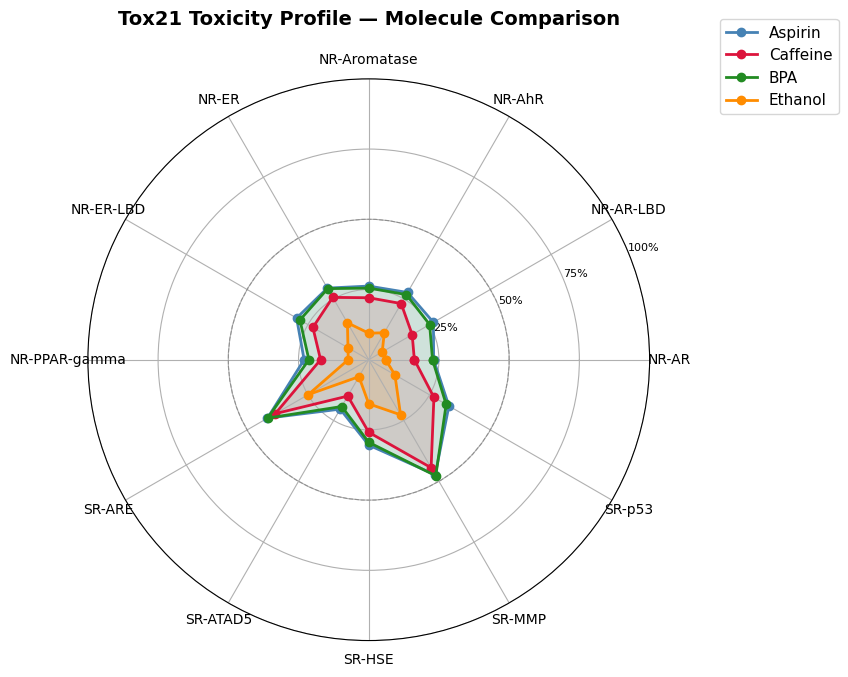

  Plot saved: radar_comparison.png


In [17]:
def radar_plot(
    probs_dict: dict,
    tasks: List[str],
    title: str = 'Toxicity Profile Comparison',
) -> None:
    """
    Draw a radar (spider) chart comparing toxicity probabilities of
    multiple molecules across all 12 Tox21 assays.

    Parameters
    ----------
    probs_dict : {molecule_name: np.ndarray of shape (12,)}
    tasks      : list of 12 task names
    """
    N = len(tasks)
    angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
    angles += angles[:1]  # close the polygon

    fig, ax = plt.subplots(figsize=(9, 9),
                           subplot_kw=dict(polar=True))

    colors = ['steelblue', 'crimson', 'forestgreen', 'darkorange']

    for (name, probs), color in zip(probs_dict.items(), colors):
        if probs is None:
            continue
        values = probs.tolist() + probs[:1].tolist()  # close polygon
        ax.plot(angles, values, 'o-', linewidth=2, color=color, label=name)
        ax.fill(angles, values, alpha=0.12, color=color)

    # Labels
    ax.set_thetagrids(np.degrees(angles[:-1]), tasks, fontsize=10)
    ax.set_ylim(0, 1)
    ax.set_yticks([0.25, 0.50, 0.75, 1.00])
    ax.set_yticklabels(['25%', '50%', '75%', '100%'], fontsize=8)
    ax.axhline(y=0.5, color='grey', linestyle='--', linewidth=0.8, alpha=0.7)

    ax.set_title(title, fontsize=14, fontweight='bold', pad=20)
    ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.12), fontsize=11)

    plt.tight_layout()
    plt.savefig('radar_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("  Plot saved: radar_comparison.png")


# ── Draw comparison radar ─────────────────────────────────────────────────────
radar_plot(
    probs_dict={
        'Aspirin'   : probs_aspirin,
        'Caffeine'  : probs_caffeine,
        'BPA'       : probs_bpa,
        'Ethanol'   : probs_ethanol,
    },
    tasks=TOX21_TASKS,
    title='Tox21 Toxicity Profile — Molecule Comparison',
)

---
## Cell 16 — Summary & Next Steps

### ✅ What We Built

| Component | Detail |
|---|---|
| **Dataset** | Tox21 via PyG MoleculeNet — 7,831 molecules, 12 assays |
| **Model** | 3-layer GCN + global mean pool + Dropout(0.5) + Linear(12) |
| **Loss** | Custom masked BCEWithLogitsLoss (handles NaN labels) |
| **Training** | Adam + ReduceLROnPlateau + Early Stopping (patience=20) |
| **Evaluation** | Per-task ROC-AUC on held-out validation set |
| **Visualisations** | NaN prevalence · Molecule graph · Training dynamics · t-SNE · Radar |
| **Inference** | `predict_new_molecule(smiles, model)` — zero extra setup |

---

### 🚀 Potential Improvements

1. **Richer node/edge features** — Use `ogb`'s atom featuriser (chirality, ring membership, MMFF charges) instead of the minimal 9-dim vector.
2. **Better architectures** — Try `GATConv` (Graph Attention) or `GINConv` (Graph Isomorphism) for more expressive message passing.
3. **Positional encodings** — Add Laplacian eigenvectors as node features (Graph Transformer style).
4. **Imbalanced class handling** — Use `pos_weight` in the BCE loss (Tox21 is heavily skewed toward non-toxic).
5. **Data augmentation** — Enumerated SMILES, molecular scaffolds, or subgraph sampling.
6. **Pre-training** — Fine-tune on a large unlabelled molecule corpus (e.g., ChEMBL, ZINC) using Masked Atom Modelling.
7. **Explainability** — Use `GNNExplainer` or `IntegratedGradients` to identify which atoms drive each toxicity prediction.

In [18]:
print("=" * 60)
print("  ✅  Notebook Complete")
print("=" * 60)
print(f"  Model architecture : ToxGCN (3×GCNConv, hidden={HIDDEN_DIM})")
print(f"  Total parameters   : {total_params:,}")
print(f"  Best val loss      : {best_val_loss:.4f}")
print(f"  Mean ROC-AUC       : {mean_auc:.4f}")
print(f"  Epochs trained     : {len(history['train_loss'])}")
print(f"  Checkpoint         : {BEST_MODEL_PATH}")
print()
print("  Generated files:")
for fname in ['nan_prevalence.png', 'molecule_graph.png',
              'training_dynamics.png', 'tsne_latent_space.png',
              'per_task_auc.png', 'radar_comparison.png',
              BEST_MODEL_PATH]:
    exists = '✅' if os.path.exists(fname) else '❌ (not yet saved)'
    print(f"    {exists}  {fname}")
print("=" * 60)

  ✅  Notebook Complete
  Model architecture : ToxGCN (3×GCNConv, hidden=128)
  Total parameters   : 35,852
  Best val loss      : 0.2032
  Mean ROC-AUC       : 0.7705
  Epochs trained     : 146
  Checkpoint         : best_tox_gcn.pt

  Generated files:
    ✅  nan_prevalence.png
    ✅  molecule_graph.png
    ✅  training_dynamics.png
    ✅  tsne_latent_space.png
    ✅  per_task_auc.png
    ✅  radar_comparison.png
    ✅  best_tox_gcn.pt
